In [1]:
import os
import sys
import gc
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
    print("GPU count:", torch.cuda.device_count())

ROOT = Path("/kaggle/input")

print("\nKaggle input:")
for p in ROOT.iterdir():
    print(" -", p)

Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
CUDA: 12.8
GPU count: 2

Kaggle input:
 - /kaggle/input/notebooks
 - /kaggle/input/competitions
 - /kaggle/input/models


In [2]:
from pathlib import Path

ROOT = Path("/kaggle/input/competitions")

print("ROOT:", ROOT)
print("\nTop-level contents:")

for p in sorted(ROOT.iterdir()):
    print(f"  {'[DIR]' if p.is_dir() else '[FILE]'} {p.name}")

ROOT: /kaggle/input/competitions

Top-level contents:
  [DIR] rsna-knee-abnormality-detection


In [3]:
print("\nDICOM directory structure:")

for p in sorted(ROOT.iterdir()):
    if p.is_dir():
        print(f"\n{p.name}/")
        for child in sorted(p.iterdir()):
            print("   ", child.name)


DICOM directory structure:

rsna-knee-abnormality-detection/
    sample_submission.csv
    test.csv
    test_series
    test_series.csv
    train.csv
    train_series
    train_series.csv


In [4]:
print("\nCSV files:")

for p in sorted(ROOT.rglob("*.csv")):
    print(p)


CSV files:
/kaggle/input/competitions/rsna-knee-abnormality-detection/sample_submission.csv
/kaggle/input/competitions/rsna-knee-abnormality-detection/test.csv
/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series.csv
/kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv
/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series.csv


In [5]:
from pathlib import Path

ROOT = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")

train_dir = ROOT / "train_series"

print("Train DICOM directory:", train_dir)
print("Exists:", train_dir.exists())

# Show first few study directories
studies = sorted([p for p in train_dir.iterdir() if p.is_dir()])

print("\nNumber of study directories:", len(studies))

print("\nFirst 5 studies:")
for p in studies[:5]:
    print(" ", p.name)

Train DICOM directory: /kaggle/input/competitions/rsna-knee-abnormality-detection/train_series
Exists: True

Number of study directories: 4407

First 5 studies:
  1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
  1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585
  1.2.826.0.1.3680043.8.498.10009278692606631573540062909909132231
  1.2.826.0.1.3680043.8.498.10009639203170750274174707434356622764
  1.2.826.0.1.3680043.8.498.10013663742400736029415768216599146542


In [6]:
# Inspect the first study
study = studies[0]

print("Selected study:", study)

series_dirs = sorted([p for p in study.iterdir() if p.is_dir()])

print("\nNumber of series:", len(series_dirs))

for s in series_dirs:
    print("Series:", s.name)
    
    dicoms = list(s.glob("*.dcm"))
    print("  DICOM files:", len(dicoms))
    print("  First files:", [x.name for x in dicoms[:3]])

Selected study: /kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260

Number of series: 5
Series: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
  DICOM files: 22
  First files: ['1.2.826.0.1.3680043.8.498.10374285052733466977592225981851620435.dcm', '1.2.826.0.1.3680043.8.498.11560456494251875828657453454342564666.dcm', '1.2.826.0.1.3680043.8.498.62696444312933722854177245172284641767.dcm']
Series: 1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265
  DICOM files: 18
  First files: ['1.2.826.0.1.3680043.8.498.12732955977266558882646974219653035510.dcm', '1.2.826.0.1.3680043.8.498.59350981989101065846464866297147921212.dcm', '1.2.826.0.1.3680043.8.498.51290044590824165461429354587015028697.dcm']
Series: 1.2.826.0.1.3680043.8.498.23084836536722595275828690293168736174
  DICOM files: 16
  First files: ['1.2.826.0.1.3680043.8.498.12098739564387780587308082414503153172.dcm', '

In [7]:
import pydicom

# First series
first_series = series_dirs[0]

# First DICOM
first_dicom = sorted(first_series.glob("*.dcm"))[0]

print("DICOM:", first_dicom)

ds = pydicom.dcmread(first_dicom)

print("\n--- DICOM metadata ---")

fields = [
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "SOPInstanceUID",
    "Modality",
    "SeriesDescription",
    "ProtocolName",
    "ImageType",
    "Rows",
    "Columns",
    "PixelSpacing",
    "SliceThickness",
    "SpacingBetweenSlices",
    "ImagePositionPatient",
    "ImageOrientationPatient",
    "InstanceNumber",
    "PhotometricInterpretation",
]

for field in fields:
    value = getattr(ds, field, "NOT PRESENT")
    print(f"{field:30s}: {value}")

DICOM: /kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260/1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772/1.2.826.0.1.3680043.8.498.10374285052733466977592225981851620435.dcm

--- DICOM metadata ---
StudyInstanceUID              : 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
SeriesInstanceUID             : 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
SOPInstanceUID                : 1.2.826.0.1.3680043.8.498.10374285052733466977592225981851620435
Modality                      : MR
SeriesDescription             : DP SPIR CS_SAG
ProtocolName                  : NOT PRESENT
ImageType                     : ['ORIGINAL', 'PRIMARY', 'M_SE', 'M', 'SE']
Rows                          : 512
Columns                       : 512
PixelSpacing                  : [0.330078125, 0.330078125]
SliceThickness                : 3.4
SpacingBetweenSlices          : 4.635
I

Pixel shape: (512, 512)
Data type: uint16
Minimum: 0
Maximum: 889


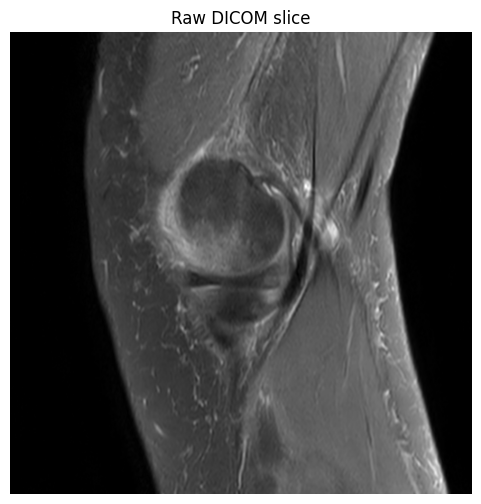

In [8]:
import matplotlib.pyplot as plt

image = ds.pixel_array

print("Pixel shape:", image.shape)
print("Data type:", image.dtype)
print("Minimum:", image.min())
print("Maximum:", image.max())

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.title("Raw DICOM slice")
plt.show()

In [9]:
print("\n===== ALL SERIES =====")

for s in series_dirs:
    dicoms = sorted(s.glob("*.dcm"))
    ds0 = pydicom.dcmread(dicoms[0], stop_before_pixels=True)

    print("\nSeries:", s.name)
    print("Number of slices:", len(dicoms))
    print("SeriesDescription:", getattr(ds0, "SeriesDescription", "N/A"))
    print("ProtocolName:", getattr(ds0, "ProtocolName", "N/A"))
    print("ImageType:", getattr(ds0, "ImageType", "N/A"))
    print("Rows x Columns:", 
          getattr(ds0, "Rows", "N/A"),
          "x",
          getattr(ds0, "Columns", "N/A"))
    print("ImageOrientationPatient:",
          getattr(ds0, "ImageOrientationPatient", "N/A"))


===== ALL SERIES =====

Series: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Number of slices: 22
SeriesDescription: DP SPIR CS_SAG
ProtocolName: N/A
ImageType: ['ORIGINAL', 'PRIMARY', 'M_SE', 'M', 'SE']
Rows x Columns: 512 x 512
ImageOrientationPatient: [-0.0334932804107, 0.99921125173568, 0.02133215218782, 0.05801957845687, 0.02325204573571, -0.9980446100234]

Series: 1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265
Number of slices: 18
SeriesDescription: STIR CS_ AX
ProtocolName: N/A
ImageType: ['ORIGINAL', 'PRIMARY', 'M_IR', 'M', 'IR']
Rows x Columns: 560 x 560
ImageOrientationPatient: [0.99478304386138, -0.1011089235544, 0.01355419494211, 0.09998968243598, 0.99273771047592, 0.06688710302114]

Series: 1.2.826.0.1.3680043.8.498.23084836536722595275828690293168736174
Number of slices: 16
SeriesDescription: T1_TSE_CS
ProtocolName: N/A
ImageType: ['ORIGINAL', 'PRIMARY', 'M_SE', 'M', 'SE']
Rows x Columns: 576 x 576
ImageOrientationPatient: [0.9968222

In [10]:
import pydicom
from pathlib import Path

# Our selected study
study = studies[0]

# First series
first_series = sorted([
    p for p in study.iterdir()
    if p.is_dir()
])[0]

# Select one DICOM file
first_dicom = sorted(first_series.glob("*.dcm"))[0]

print("DICOM file:")
print(first_dicom)

# Read DICOM
ds = pydicom.dcmread(first_dicom)

print("\nDICOM information:")
print("Study UID:", ds.StudyInstanceUID)
print("Series UID:", ds.SeriesInstanceUID)
print("Rows:", ds.Rows)
print("Columns:", ds.Columns)
print("Modality:", ds.Modality)
print("Series description:", ds.SeriesDescription)

DICOM file:
/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260/1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772/1.2.826.0.1.3680043.8.498.10374285052733466977592225981851620435.dcm

DICOM information:
Study UID: 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
Series UID: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Rows: 512
Columns: 512
Modality: MR
Series description: DP SPIR CS_SAG


In [11]:
image = ds.pixel_array

print("Image shape:", image.shape)
print("Data type:", image.dtype)
print("Minimum pixel value:", image.min())
print("Maximum pixel value:", image.max())

Image shape: (512, 512)
Data type: uint16
Minimum pixel value: 0
Maximum pixel value: 889


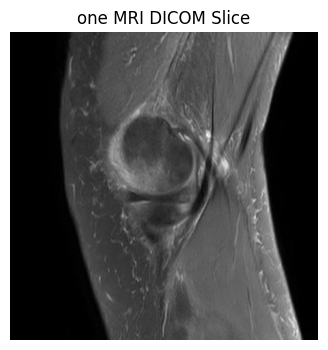

In [12]:
import matplotlib.pyplot as plt 

plt.figure(figsize=(4,4))
plt.imshow(image,cmap="gray")
plt.axis("off")
plt.title("one MRI DICOM Slice")
plt.show()

In [13]:
import pydicom
import pandas as pd

# Our first series: DP SPIR CS_SAG
first_series = sorted([
    p for p in studies[0].iterdir()
    if p.is_dir()
])[0]

records = []

for path in first_series.glob("*.dcm"):
    ds = pydicom.dcmread(path, stop_before_pixels=True)

    records.append({
        "file": path.name,
        "instance_number": getattr(ds, "InstanceNumber", None),
        "x": ds.ImagePositionPatient[0],
        "y": ds.ImagePositionPatient[1],
        "z": ds.ImagePositionPatient[2],
    })

position_df = pd.DataFrame(records)

display(position_df)

,file,instance_number,x,y,z
0,1.2.826.0.1.3680043.8.498.10374285052733466977...,5,-80.965252,-143.119428,98.546741
1,1.2.826.0.1.3680043.8.498.11560456494251875828...,2,-67.092823,-142.671869,99.363618
2,1.2.826.0.1.3680043.8.498.62696444312933722854...,15,-127.206661,-144.611295,95.823821
3,1.2.826.0.1.3680043.8.498.13270416360166070027...,12,-113.334240,-144.163736,96.640697
4,1.2.826.0.1.3680043.8.498.16282623942824367613...,13,-117.958378,-144.312925,96.368405
5,1.2.826.0.1.3680043.8.498.10986732409717781858...,3,-71.716969,-142.821058,99.091325
6,1.2.826.0.1.3680043.8.498.92820762186965516661...,17,-136.454945,-144.909670,95.279237
7,1.2.826.0.1.3680043.8.498.59737936249480831062...,20,-150.327366,-145.357229,94.462360
8,1.2.826.0.1.3680043.8.498.93755789787124953238...,4,-76.341107,-142.970243,98.819034
9,1.2.826.0.1.3680043.8.498.33690734911291064161...,14,-122.582524,-144.462110,96.096113


In [14]:
print(position_df[["instance_number", "x", "y", "z"]]
      .sort_values("z")
      .to_string(index=False))

 instance_number           x           y         z
              22 -159.575657 -145.655603 93.917776
              21 -154.951512 -145.506418 94.190068
              20 -150.327366 -145.357229 94.462360
              19 -145.703221 -145.208044 94.734653
              18 -141.079090 -145.058859 95.006945
              17 -136.454945 -144.909670 95.279237
              16 -131.830799 -144.760484 95.551529
              15 -127.206661 -144.611295 95.823821
              14 -122.582524 -144.462110 96.096113
              13 -117.958378 -144.312925 96.368405
              12 -113.334240 -144.163736 96.640697
              11 -108.710095 -144.014551 96.912989
              10 -104.085957 -143.865362 97.185281
               9  -99.461811 -143.716177 97.457573
               8  -94.837673 -143.566992 97.729865
               7  -90.213535 -143.417803 98.002157
               6  -85.589390 -143.268617 98.274449
               5  -80.965252 -143.119428 98.546741
               4  -76.341107 -1

In [15]:
import pydicom
import numpy as np
from pathlib import Path


def load_dicom_series(series_dir):
    """
    Load one DICOM series.

    Returns:
        volume: NumPy array with shape (num_slices, height, width)
        datasets: DICOM metadata objects in slice order
    """

    # 1. Find all DICOM files
    files = list(Path(series_dir).glob("*.dcm"))

    if len(files) == 0:
        raise ValueError(f"No DICOM files found in {series_dir}")

    # 2. Read metadata + image
    slices = []

    for file in files:
        ds = pydicom.dcmread(file)

        # Make sure spatial position exists
        if hasattr(ds, "ImagePositionPatient"):
            position = np.array(ds.ImagePositionPatient, dtype=np.float64)
        else:
            position = None

        slices.append({
            "ds": ds,
            "position": position,
            "file": file
        })

    # 3. For now, sort using the slice Z position
    #    This works for our current series and lets us
    #    understand the pipeline before making it fully
    #    orientation-aware.
    if all(x["position"] is not None for x in slices):
        slices.sort(key=lambda x: x["position"][2])
    else:
        slices.sort(
            key=lambda x: getattr(x["ds"], "InstanceNumber", 0)
        )

    # 4. Extract pixel arrays
    images = []

    for item in slices:
        image = item["ds"].pixel_array
        images.append(image)

    # 5. Convert list → NumPy volume
    volume = np.stack(images, axis=0)

    datasets = [x["ds"] for x in slices]

    return volume, datasets

In [16]:
first_series = sorted([
    p for p in studies[0].iterdir()
    if p.is_dir()
])[0]

volume, metadata = load_dicom_series(first_series)

print("Series:", first_series.name)
print("Number of slices:", volume.shape[0])
print("Image height:", volume.shape[1])
print("Image width:", volume.shape[2])
print("Volume shape:", volume.shape)

Series: 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772
Number of slices: 22
Image height: 512
Image width: 512
Volume shape: (22, 512, 512)


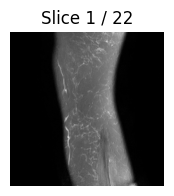

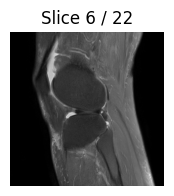

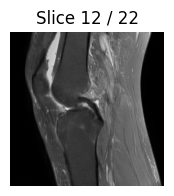

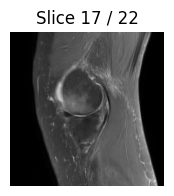

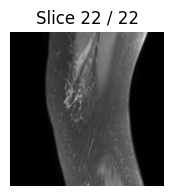

In [17]:
import matplotlib.pyplot as plt

indices = [
    0,
    len(volume) // 4,
    len(volume) // 2,
    3 * len(volume) // 4,
    len(volume) - 1
]

for idx in indices:

    plt.figure(figsize=(2, 2))

    plt.imshow(volume[idx], cmap="gray")

    plt.title(f"Slice {idx + 1} / {len(volume)}")
    plt.axis("off")

    plt.show()

In [18]:
print("Volume shape:", volume.shape)
print("Data type:", volume.dtype)

print("Minimum:", volume.min())
print("Maximum:", volume.max())
print("Mean:", volume.mean())
print("Standard deviation:", volume.std())

Volume shape: (22, 512, 512)
Data type: uint16
Minimum: 0
Maximum: 1054
Mean: 199.07568342035466
Standard deviation: 173.6067825192489


In [19]:
volume_float = volume.astype(np.float32)

vmin = volume_float.min()
vmax = volume_float.max()

volume_norm = (volume_float - vmin) / (vmax - vmin + 1e-8)

print("Normalized minimum:", volume_norm.min())
print("Normalized maximum:", volume_norm.max())
print("Normalized dtype:", volume_norm.dtype)

Normalized minimum: 0.0
Normalized maximum: 1.0
Normalized dtype: float32


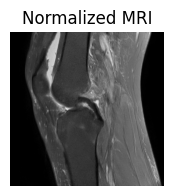

In [20]:
plt.figure(figsize=(2, 2))

plt.imshow(volume_norm[len(volume_norm)//2], cmap="gray")

plt.title("Normalized MRI")
plt.axis("off")
plt.show()

orginal: (512, 512)
Resized: (224, 224)


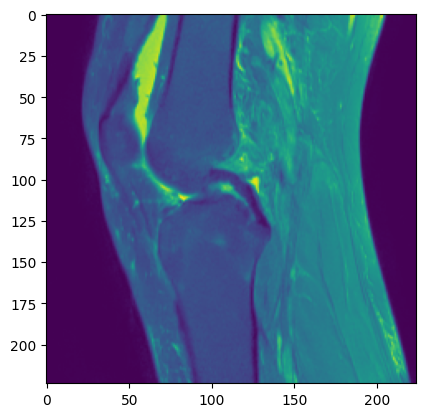

In [21]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
slice_img = volume_norm[len(volume_norm)//2]
slice_uint8 =(slice_img*255).clip(0,255).astype(np.uint8)
pil_img = Image.fromarray(slice_uint8)

resized_img = pil_img.resize(
    (224, 224),
    Image.Resampling.BILINEAR
)

plt.imshow(resized_img)
print("orginal:",pil_img.size)
print("Resized:",resized_img.size)

Resized image shape: (224, 224)
Data type: uint8
Original shape: (224, 224)
RGB shape: (224, 224, 3)


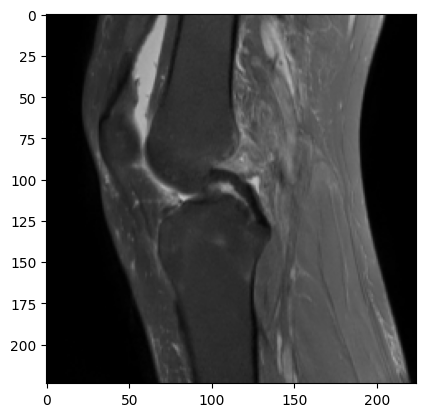

In [22]:
resized_array = np.array(resized_img)

print("Resized image shape:", resized_array.shape)
print("Data type:", resized_array.dtype)

slice_rgb = np.stack(
    [resized_array, resized_array, resized_array],
    axis=-1
)

print("Original shape:", resized_array.shape)
print("RGB shape:", slice_rgb.shape)
plt.imshow(slice_rgb)

In [23]:
print(type(slice_rgb))
print(slice_rgb.shape)

import torch

tensor = torch.from_numpy(slice_rgb)
tensor = tensor.permute(2,0,1)
tensor = tensor.unsqueeze(0)
print(type(tensor))
print(tensor.shape)
print(tensor.dtype)


<class 'numpy.ndarray'>
(224, 224, 3)
<class 'torch.Tensor'>
torch.Size([1, 3, 224, 224])
torch.uint8


In [24]:
from pathlib import Path

print("=== KAGGLE INPUTS ===")

for p in Path("/kaggle/input").iterdir():
    print(p)

=== KAGGLE INPUTS ===
/kaggle/input/notebooks
/kaggle/input/competitions
/kaggle/input/models


In [25]:
import keras
import keras_hub

print("keras:",keras.__version__)
print("kerashub:",keras_hub.__version__)

dinov3=keras_hub.models.DINOV3Backbone.from_preset(
    "dinov3_vit_base_lvd1689m"
)
print(dinov3)

keras: 3.13.2
kerashub: 0.26.0


I0000 00:00:1792721703.373638      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792721703.377909      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


<DINOV3Backbone name=dinov3_backbone, built=True>


In [26]:
print("Model type:")
print(type(dinov3))

print("\nModel name:")
print(dinov3.name)

print("\nModel summary:")
dinov3.summary()

Model type:
<class 'keras_hub.src.models.dinov3.dinov3_backbone.DINOV3Backbone'>

Model name:
dinov3_backbone

Model summary:


Model: "dinov3_backbone"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ pixel_values        │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dinov3_backbone_em… │ (None, 201, 768)  │    595,200 │ pixel_values[0][… │
│ (DINOV3Embedding)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dinov3_backbone_ro… │ [(196, 64), (196, │          0 │ pixel_values[0][… │
│ (DINOV3RopePositio… │ 64)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dinov3_backbone_en… │ [(None, 201,      │ 85,063,680 │ dinov3_backbone_… │
│ (DINOV3Encoder)     │ 768), (None, 201, │            │ dinov3_backbone_… │
│                     │ 768), (None, 201, │            │ dinov3_backbone_… │
│                     │ 768), (None, 201, │            │                   │
│                     │ 768), (None, 201, │            │                   │
│                     │ 768), (None, 201, │            │                   │
│                     │ 768), (None, 201, │            │                   │
│                     │ 768), (None, 201, │            │                   │
│                     │ 768), (None, 201, │            │                   │
│                     │ 768), (None, 201, │            │                   │
│                     │ 768), (None, 201, │            │                   │
│                     │ 768), (None, 201, │            │                   │
│                     │ 768), (None, 201, │            │                   │
│                     │ 768)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dinov3_backbone_la… │ (None, 201, 768)  │      1,536 │ dinov3_backbone_… │
│ (LayerNormalizatio… │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 85,660,416 (326.77 MB)

 Trainable params: 85,660,416 (326.77 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
slice_array = np.array(resized_img)

print("Shape:", slice_array.shape)
print("Data type:", slice_array.dtype)
print("Min:", slice_array.min())
print("Max:", slice_array.max())

Shape: (224, 224)
Data type: uint8
Min: 0
Max: 197


In [28]:
slice_batch = np.expand_dims(slice_rgb, axis=0)

print("Batch shape:", slice_batch.shape)

Batch shape: (1, 224, 224, 3)


In [29]:
features = dinov3(slice_batch)

print("Output type:", type(features))
print("Output shape:", features.shape)

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: {'pixel_values': 'pixel_values'}
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


Output type: <class 'tensorflow.python.framework.ops.EagerTensor'>
Output shape: (1, 201, 768)


In [30]:
print("Feature shape:", features.shape)

print("\nFeature dtype:", features.dtype)

print("\nFeature statistics:")
print("Min:", features.numpy().min())
print("Max:", features.numpy().max())
print("Mean:", features.numpy().mean())
print("Std:", features.numpy().std())

Feature shape: (1, 201, 768)

Feature dtype: <dtype: 'float32'>

Feature statistics:
Min: -11.8346195
Max: 12.970971
Mean: 0.0059759496
Std: 0.63669056


In [31]:
first_token = features[:,0,:]
print("first token shape:",first_token.shape)
print(first_token[0,:10])

first token shape: (1, 768)
tf.Tensor(
[ 0.07809941  0.32738104  0.6242084  -0.5258715   0.76644146 -0.15151045
 -0.17913991  0.27013832  0.57874    -0.5937771 ], shape=(10,), dtype=float32)


In [32]:
print("Slice feature shape:",first_token.shape)
print("Slice feature dtype:",first_token.dtype)
slice_feature = first_token.numpy()[0]
print(slice_feature.shape)

Slice feature shape: (1, 768)
Slice feature dtype: <dtype: 'float32'>
(768,)


In [33]:
from PIL import Image
import numpy as np

def preprocess_mri_slice(slice_img):
    """
    Convert one normalized MRI slice into
    the input format expected by DINOv3.

    Input:
        slice_img: (H, W), values approximately 0–1

    Output:
        (1, 224, 224, 3)
    """

    # 1. Convert normalized float image → uint8
    slice_uint8 = (
        slice_img * 255
    ).clip(0, 255).astype(np.uint8)

    # 2. NumPy → PIL
    pil_img = Image.fromarray(slice_uint8)

    # 3. Resize to DINOv3 input size
    resized_img = pil_img.resize(
        (224, 224),
        Image.Resampling.BILINEAR
    )

    # 4. PIL → NumPy
    slice_array = np.array(resized_img)

    # 5. Grayscale → 3 channels
    slice_rgb = np.stack(
        [slice_array, slice_array, slice_array],
        axis=-1
    )

    # 6. Add batch dimension
    slice_batch = np.expand_dims(
        slice_rgb,
        axis=0
    )

    return slice_batch

In [34]:
def extract_slice_feature(slice_img):
    """
    Convert one MRI slice into a 768-dimensional
    DINOv3 feature vector.
    """

    # Prepare image
    image = preprocess_mri_slice(slice_img)

    # DINOv3 inference
    output = dinov3(image)

    # Take token 0
    feature = output[:, 0, :]

    # Remove batch dimension
    feature = feature.numpy()[0]

    return feature

In [35]:
series_features = []

for i, slice_img in enumerate(volume_norm):

    feature = extract_slice_feature(slice_img)

    series_features.append(feature)

    print(
        f"Slice {i+1}/{len(volume_norm)} "
        f"→ {feature.shape}"
    )

Slice 1/22 → (768,)
Slice 2/22 → (768,)
Slice 3/22 → (768,)
Slice 4/22 → (768,)
Slice 5/22 → (768,)
Slice 6/22 → (768,)
Slice 7/22 → (768,)
Slice 8/22 → (768,)
Slice 9/22 → (768,)
Slice 10/22 → (768,)
Slice 11/22 → (768,)
Slice 12/22 → (768,)
Slice 13/22 → (768,)
Slice 14/22 → (768,)
Slice 15/22 → (768,)
Slice 16/22 → (768,)
Slice 17/22 → (768,)
Slice 18/22 → (768,)
Slice 19/22 → (768,)
Slice 20/22 → (768,)
Slice 21/22 → (768,)
Slice 22/22 → (768,)


In [36]:
series_features=np.stack(series_features)
print("series features shape:",series_features.shape)

series features shape: (22, 768)


In [37]:
series_feature_mean = series_features.mean(axis=0)

print("Original:", series_features.shape)
print("Aggregated:", series_feature_mean.shape)

series_feature_max = series_features.max(axis=0)

print("Max pooled shape:", series_feature_max.shape)

print("Mean pooling:")
print("  Shape:", series_feature_mean.shape)
print("  Mean:", series_feature_mean.mean())
print("  Std :", series_feature_mean.std())

print("\nMax pooling:")
print("  Shape:", series_feature_max.shape)
print("  Mean:", series_feature_max.mean())
print("  Std :", series_feature_max.std())

Original: (22, 768)
Aggregated: (768,)
Max pooled shape: (768,)
Mean pooling:
  Shape: (768,)
  Mean: 0.006111048
  Std : 0.5573565

Max pooling:
  Shape: (768,)
  Mean: 0.21811028
  Std : 0.5594565


In [38]:
def extract_series_feature(series_dir):

    dicom_files = sorted(series_dir.glob("*.dcm"))

    slice_features = []

    for file in dicom_files:

        # Read DICOM
        ds = pydicom.dcmread(file)

        # Pixel data
        image = ds.pixel_array.astype(np.float32)

        # Normalize
        image_min = image.min()
        image_max = image.max()

        image_norm = (
            image - image_min
        ) / (
            image_max - image_min + 1e-8
        )

        # Prepare image
        model_input = preprocess_mri_slice(image_norm)

        # IMPORTANT:
        # DINOv3 expects a named input
        output = dinov3({
            "pixel_values": model_input
        })

        # Token 0
        feature = output[:, 0, :]

        # Tensor → NumPy → remove batch dimension
        feature = feature.numpy()[0]

        slice_features.append(feature)

    # (number_of_slices, 768)
    slice_features = np.stack(slice_features)

    # Mean pooling across slices
    series_feature = slice_features.mean(axis=0)

    return series_feature, len(dicom_files)

In [39]:
test_feature, test_count = extract_series_feature(
    series_dirs[0]
)

print("Number of slices:", test_count)
print("Feature shape:", test_feature.shape)

Number of slices: 22
Feature shape: (768,)


In [40]:
print("=== CURRENT PIPELINE CHECK ===")

print("DINOv3 loaded:", "dinov3" in globals())
print("Preprocessing function:", "preprocess_mri_slice" in globals())
print("Series function:", "extract_series_feature" in globals())
print("Series directories:", "series_dirs" in globals())

if "series_dirs" in globals():
    print("Number of series:", len(series_dirs))

if "series_feature" in globals():
    print("Current series feature:", series_feature.shape)

if "num_slices" in globals():
    print("Current series slices:", num_slices)

=== CURRENT PIPELINE CHECK ===
DINOv3 loaded: True
Preprocessing function: True
Series function: True
Series directories: True
Number of series: 5


In [41]:
import pandas as pd

DATA_ROOT = Path(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection"
)

train_csv = DATA_ROOT / "train.csv"

train_df = pd.read_csv(train_csv)

print("Shape:", train_df.shape)
print("\nColumns:")
print(train_df.columns.tolist())

print("\nFirst 5 rows:")
display(train_df.head())

Shape: (4407, 14)

Columns:
['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']

First 5 rows:


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,Técnica: RMN de la rodilla. Resultados: Rotura...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,Hallazgos:\nNo hay alteraciones en significati...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,"In the medial compartment, the meniscus is no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,CONSTATATIONS :\n\nFractures :\nAucune.\n\nAli...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [42]:
target_columns = [
    'ACL',
    'MCL',
    'Medial Meniscus',
    'Lateral Meniscus',
    'Medial OA',
    'Lateral OA',
    'PF OA',
    'Effusion',
    'Synovitis',
    "Baker's",
    'Contusion',
    'Fracture'
]

for col in target_columns:
    print(f"\n=== {col} ===")
    print(train_df[col].value_counts(dropna=False))


=== ACL ===
ACL
NaN    4349
0.0      34
1.0      24
Name: count, dtype: int64

=== MCL ===
MCL
NaN    4349
0.0      49
1.0       9
Name: count, dtype: int64

=== Medial Meniscus ===
Medial Meniscus
NaN    4349
0.0      32
1.0      26
Name: count, dtype: int64

=== Lateral Meniscus ===
Lateral Meniscus
NaN    4349
0.0      35
1.0      23
Name: count, dtype: int64

=== Medial OA ===
Medial OA
NaN    4349
0.0      43
1.0      15
Name: count, dtype: int64

=== Lateral OA ===
Lateral OA
NaN    4349
0.0      47
1.0      11
Name: count, dtype: int64

=== PF OA ===
PF OA
NaN    4349
0.0      37
1.0      21
Name: count, dtype: int64

=== Effusion ===
Effusion
NaN    4349
1.0      35
0.0      23
Name: count, dtype: int64

=== Synovitis ===
Synovitis
NaN    4349
0.0      31
1.0      27
Name: count, dtype: int64

=== Baker's ===
Baker's
NaN    4349
0.0      46
1.0      12
Name: count, dtype: int64

=== Contusion ===
Contusion
NaN    4349
0.0      39
1.0      19
Name: count, dtype: int64

=== Frac

In [43]:
target_columns = [
    'ACL',
    'MCL',
    'Medial Meniscus',
    'Lateral Meniscus',
    'Medial OA',
    'Lateral OA',
    'PF OA',
    'Effusion',
    'Synovitis',
    "Baker's",
    'Contusion',
    'Fracture'
]

# Studies where at least one target is labeled
labeled_df = train_df[
    train_df[target_columns].notna().any(axis=1)
].copy()

print("Total studies:", len(train_df))
print("Labeled studies:", len(labeled_df))
print("Unlabeled studies:", len(train_df) - len(labeled_df))

print("\nLabel matrix shape:")
print(labeled_df[target_columns].shape)

display(
    labeled_df[
        ['StudyInstanceUID'] + target_columns
    ].head(10)
)

Total studies: 4407
Labeled studies: 58
Unlabeled studies: 4349

Label matrix shape:
(58, 12)


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
29,1.2.826.0.1.3680043.8.498.10095687747295410396...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
63,1.2.826.0.1.3680043.8.498.10170898615867673028...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
109,1.2.826.0.1.3680043.8.498.10306159113324811538...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
445,1.2.826.0.1.3680043.8.498.11287937729196958426...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
470,1.2.826.0.1.3680043.8.498.11382021393803389951...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
533,1.2.826.0.1.3680043.8.498.11548045715264151632...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
537,1.2.826.0.1.3680043.8.498.11557620559191469069...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
607,1.2.826.0.1.3680043.8.498.11771393824519892797...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
632,1.2.826.0.1.3680043.8.498.11851412923016044948...,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
656,1.2.826.0.1.3680043.8.498.11915937982684988073...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0


In [44]:
print(
    "Rows with all 12 labels:",
    labeled_df[target_columns].notna().all(axis=1).sum()
)

print(
    "Rows with some missing labels:",
    labeled_df[target_columns].isna().any(axis=1).sum()
)

Rows with all 12 labels: 58
Rows with some missing labels: 0


In [45]:
# Study IDs
study_ids = labeled_df["StudyInstanceUID"].values

# Target labels
y = labeled_df[target_columns].values.astype(np.float32)

print("Study IDs:", study_ids.shape)
print("Labels:", y.shape)
print("\nFirst label row:")
print(y[0])

Study IDs: (58,)
Labels: (58, 12)

First label row:
[0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0.]


In [46]:
TRAIN_SERIES_ROOT = DATA_ROOT / "train_series"

available = 0
missing = []

for uid in study_ids:

    study_dir = TRAIN_SERIES_ROOT / uid

    if study_dir.exists():
        available += 1
    else:
        missing.append(uid)

print("Labeled studies:", len(study_ids))
print("DICOM studies found:", available)
print("Missing:", len(missing))

if missing:
    print("\nFirst missing IDs:")
    for uid in missing[:5]:
        print(uid)

Labeled studies: 58
DICOM studies found: 58
Missing: 0


In [47]:
test_uid = study_ids[0]

test_study_dir = TRAIN_SERIES_ROOT / test_uid

print("Study UID:")
print(test_uid)

print("\nStudy directory:")
print(test_study_dir)

test_series_dirs = sorted([
    p for p in test_study_dir.iterdir()
    if p.is_dir()
])

print("\nNumber of series:",
      len(test_series_dirs))

for s in test_series_dirs:
    print(
        s.name,
        "→",
        len(list(s.glob("*.dcm"))),
        "slices"
    )

Study UID:
1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149

Study directory:
/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149

Number of series: 5
1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282 → 36 slices
1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441 → 30 slices
1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198 → 30 slices
1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429 → 36 slices
1.2.826.0.1.3680043.8.498.67495435033389756963800730529101229430 → 32 slices


In [48]:
def extract_study_feature(study_dir):
    """
    Extract one 768-D feature representing an entire MRI study.

    Study
      ↓
    multiple series
      ↓
    DINOv3 slice features
      ↓
    mean pooling per series
      ↓
    mean pooling across series
      ↓
    768-D study feature
    """

    series_dirs = sorted([
        p for p in study_dir.iterdir()
        if p.is_dir()
    ])

    series_features = []

    for i, series_dir in enumerate(series_dirs):

        print(
            f"  Series {i+1}/{len(series_dirs)}: "
            f"{series_dir.name}"
        )

        feature, num_slices = extract_series_feature(
            series_dir
        )

        series_features.append(feature)

        print(
            f"    Slices: {num_slices}"
            f" | Feature: {feature.shape}"
        )

    # Convert:
    # [768, 768, ...] → (number_of_series, 768)
    series_features = np.stack(series_features)

    # Aggregate series
    study_feature = series_features.mean(axis=0)

    return study_feature

In [49]:
print("Testing study feature extraction...\n")

test_feature = extract_study_feature(
    test_study_dir
)

print("\n==============================")
print("Final study feature shape:")
print(test_feature.shape)

Testing study feature extraction...

  Series 1/5: 1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282
    Slices: 36 | Feature: (768,)
  Series 2/5: 1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441
    Slices: 30 | Feature: (768,)
  Series 3/5: 1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198
    Slices: 30 | Feature: (768,)
  Series 4/5: 1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429
    Slices: 36 | Feature: (768,)
  Series 5/5: 1.2.826.0.1.3680043.8.498.67495435033389756963800730529101229430
    Slices: 32 | Feature: (768,)

Final study feature shape:
(768,)


In [50]:
# Take one slice
test_slice = pydicom.dcmread(
    sorted(test_series_dirs[0].glob("*.dcm"))[0]
).pixel_array.astype(np.float32)

# Normalize
test_slice = (
    test_slice - test_slice.min()
) / (
    test_slice.max() - test_slice.min() + 1e-8
)

# Preprocess
test_input = preprocess_mri_slice(test_slice)

print("Input shape:", test_input.shape)
print("Input dtype:", test_input.dtype)

# Correct named input
test_output = dinov3({
    "pixel_values": test_input
})

print("\nOutput type:", type(test_output))

if isinstance(test_output, dict):
    print("Output keys:", test_output.keys())
    
    for key, value in test_output.items():
        print(
            key,
            "→",
            value.shape,
            value.dtype
        )
else:
    print("Output shape:", test_output.shape)

Input shape: (1, 224, 224, 3)
Input dtype: uint8

Output type: <class 'tensorflow.python.framework.ops.EagerTensor'>
Output shape: (1, 201, 768)


In [51]:
print("Testing complete study...\n")

test_feature = extract_study_feature(
    test_study_dir
)

print("\n==============================")
print("Final study feature shape:")
print(test_feature.shape)

Testing complete study...

  Series 1/5: 1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282
    Slices: 36 | Feature: (768,)
  Series 2/5: 1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441
    Slices: 30 | Feature: (768,)
  Series 3/5: 1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198
    Slices: 30 | Feature: (768,)
  Series 4/5: 1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429
    Slices: 36 | Feature: (768,)
  Series 5/5: 1.2.826.0.1.3680043.8.498.67495435033389756963800730529101229430
    Slices: 32 | Feature: (768,)

Final study feature shape:
(768,)


In [52]:
from pathlib import Path
import numpy as np

FEATURE_DIR = Path("/kaggle/working/dinov3_features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

print("Feature directory:", FEATURE_DIR)

Feature directory: /kaggle/working/dinov3_features


In [53]:
test_uid = study_ids[0]

feature_path = FEATURE_DIR / f"{test_uid}.npy"

np.save(feature_path, test_feature)

print("Saved:", feature_path)
print("Shape:", test_feature.shape)

Saved: /kaggle/working/dinov3_features/1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149.npy
Shape: (768,)


In [54]:
loaded_feature = np.load(feature_path)

print("Loaded feature shape:", loaded_feature.shape)
print("Data type:", loaded_feature.dtype)
print("First 10 values:", loaded_feature[:10])

Loaded feature shape: (768,)
Data type: float32
First 10 values: [-0.14834881 -0.0889895   0.51549476 -0.51905644  0.56471336  0.37445483
 -0.03013343 -0.1498678   0.3213283  -0.49562916]


In [55]:
import pydicom
import numpy as np

def get_sorted_dicom_files(series_dir):
    files = list(series_dir.glob("*.dcm"))

    dicoms = []

    for file in files:
        ds = pydicom.dcmread(
            file,
            stop_before_pixels=True
        )

        position = getattr(
            ds,
            "ImagePositionPatient",
            None
        )

        if position is not None:
            # Position along slice direction.
            # For a general orientation, use the slice normal.
            orientation = getattr(
                ds,
                "ImageOrientationPatient",
                None
            )

            if orientation is not None:
                row = np.array(
                    orientation[:3],
                    dtype=np.float64
                )

                col = np.array(
                    orientation[3:],
                    dtype=np.float64
                )

                normal = np.cross(row, col)

                location = np.dot(
                    np.array(position, dtype=np.float64),
                    normal
                )
            else:
                location = float(position[2])

        else:
            location = getattr(
                ds,
                "InstanceNumber",
                0
            )

        dicoms.append(
            (file, location)
        )

    dicoms.sort(key=lambda x: x[1])

    return [x[0] for x in dicoms]

In [56]:
ordered_files = get_sorted_dicom_files(
    test_series_dirs[0]
)

print("Number of slices:", len(ordered_files))

print("\nFirst 5:")
for f in ordered_files[:5]:
    print(f.name)

print("\nLast 5:")
for f in ordered_files[-5:]:
    print(f.name)

Number of slices: 36

First 5:
1.2.826.0.1.3680043.8.498.91446960268429747548361089814727880161.dcm
1.2.826.0.1.3680043.8.498.38959228348903507367790219482236396198.dcm
1.2.826.0.1.3680043.8.498.73302834479106869281559375054301358023.dcm
1.2.826.0.1.3680043.8.498.65534874389165091712907703748113641701.dcm
1.2.826.0.1.3680043.8.498.12794866797780490569795169059496764145.dcm

Last 5:
1.2.826.0.1.3680043.8.498.83097921602838518605535174051186672979.dcm
1.2.826.0.1.3680043.8.498.10570231435215360827078428550187913606.dcm
1.2.826.0.1.3680043.8.498.13293329077369859170522534453218530517.dcm
1.2.826.0.1.3680043.8.498.35997826039645946364175701678359697971.dcm
1.2.826.0.1.3680043.8.498.54713014478057088900296041720692046524.dcm


In [57]:
def prepare_slice_for_dinov3(dicom_file):
    ds = pydicom.dcmread(dicom_file)

    image = ds.pixel_array.astype(np.float32)

    # Normalize MRI intensity
    image_min = image.min()
    image_max = image.max()

    image_norm = (
        image - image_min
    ) / (
        image_max - image_min + 1e-8
    )

    # Existing preprocessing function
    return preprocess_mri_slice(image_norm)

In [58]:
def extract_series_feature_batched(
    series_dir,
    batch_size=32
):

    dicom_files = get_sorted_dicom_files(series_dir)

    all_features = []

    for start in range(0, len(dicom_files), batch_size):

        batch_files = dicom_files[
            start:start + batch_size
        ]

        batch_images = []

        for file in batch_files:
            image = prepare_slice_for_dinov3(file)
            batch_images.append(image)

        # Combine slices into one batch
        batch_images = np.concatenate(
            batch_images,
            axis=0
        )

        # DINOv3 named input
        output = dinov3({
            "pixel_values": batch_images
        })

        # First token → 768 dimensions
        features = output[:, 0, :]

        features = features.numpy()

        all_features.append(features)

        print(
            f"  Processed "
            f"{start + len(batch_files)}/{len(dicom_files)} slices"
        )

    # (total_slices, 768)
    all_features = np.concatenate(
        all_features,
        axis=0
    )

    # Series-level mean pooling
    series_feature = all_features.mean(axis=0)

    return series_feature, len(dicom_files)

In [59]:
test_feature, test_count = extract_series_feature_batched(
    test_series_dirs[0],
    batch_size=32
)

print("\n==============================")
print("Slices:", test_count)
print("Feature shape:", test_feature.shape)

  Processed 32/36 slices
  Processed 36/36 slices

Slices: 36
Feature shape: (768,)


In [60]:
def extract_study_feature_batched(study_dir, batch_size=16):

    series_dirs = sorted([
        p for p in study_dir.iterdir()
        if p.is_dir()
    ])

    series_features = []

    print(f"Number of series: {len(series_dirs)}")

    for i, series_dir in enumerate(series_dirs):

        print(
            f"\n  Series {i+1}/{len(series_dirs)}"
        )
        print(
            f"  Series ID: {series_dir.name}"
        )

        feature, num_slices = extract_series_feature_batched(
            series_dir,
            batch_size=batch_size
        )

        series_features.append(feature)

        print(
            f"  Completed: {num_slices} slices"
        )
        print(
            f"  Series feature: {feature.shape}"
        )

    # (number_of_series, 768)
    series_features = np.stack(series_features)

    # Study-level aggregation
    study_feature = series_features.mean(axis=0)

    return study_feature

In [61]:
test_uid = study_ids[0]

test_study_dir = TRAIN_SERIES_ROOT / test_uid

print("Testing study:")
print(test_uid)

test_study_feature = extract_study_feature_batched(
    test_study_dir,
    batch_size=16
)

print("\n==============================")
print("FINAL STUDY FEATURE")
print("==============================")
print("Shape:", test_study_feature.shape)
print("Dtype:", test_study_feature.dtype)
print("Min:", test_study_feature.min())
print("Max:", test_study_feature.max())
print("Mean:", test_study_feature.mean())
print("Std:", test_study_feature.std())

Testing study:
1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149
Number of series: 5

  Series 1/5
  Series ID: 1.2.826.0.1.3680043.8.498.10791858932231443712736629517371931282
  Processed 16/36 slices
  Processed 32/36 slices
  Processed 36/36 slices
  Completed: 36 slices
  Series feature: (768,)

  Series 2/5
  Series ID: 1.2.826.0.1.3680043.8.498.12451507871565834868863189854063726441
  Processed 16/30 slices
  Processed 30/30 slices
  Completed: 30 slices
  Series feature: (768,)

  Series 3/5
  Series ID: 1.2.826.0.1.3680043.8.498.21497837050858589852101556928971904198
  Processed 16/30 slices
  Processed 30/30 slices
  Completed: 30 slices
  Series feature: (768,)

  Series 4/5
  Series ID: 1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429
  Processed 16/36 slices
  Processed 32/36 slices
  Processed 36/36 slices
  Completed: 36 slices
  Series feature: (768,)

  Series 5/5
  Series ID: 1.2.826.0.1.3680043.8.498.6749543503338975696380073052910122943

In [62]:
FEATURE_DIR = Path("/kaggle/working/dinov3_features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

In [63]:
import time
import numpy as np

successful = []
failed = []

for i, uid in enumerate(study_ids):

    

    feature_path = FEATURE_DIR / f"{uid}.npy"

    # Resume support
    if feature_path.exists():

        feature = np.load(feature_path)

        if feature.shape == (768,):

            
            successful.append(uid)
            continue

        else:
            print(
                "Existing file has wrong shape. Reprocessing..."
            )

    study_dir = TRAIN_SERIES_ROOT / uid

    start = time.time()

    try:

        feature = extract_study_feature_batched(
            study_dir,
            batch_size=16
        )

        if feature.shape != (768,):
            raise ValueError(
                f"Unexpected feature shape: {feature.shape}"
            )

        # Save immediately
        np.save(feature_path, feature)

        elapsed = time.time() - start

        successful.append(uid)

        

    except Exception as e:

        failed.append(uid)

        print("\n✗ STUDY FAILED")
        print("Error:", repr(e))

Number of series: 9

  Series 1/9
  Series ID: 1.2.826.0.1.3680043.8.498.10560750949481691706699585852544080976
  Processed 16/30 slices
  Processed 30/30 slices
  Completed: 30 slices
  Series feature: (768,)

  Series 2/9
  Series ID: 1.2.826.0.1.3680043.8.498.11485276391165564447623186225915027296
  Processed 16/30 slices
  Processed 30/30 slices
  Completed: 30 slices
  Series feature: (768,)

  Series 3/9
  Series ID: 1.2.826.0.1.3680043.8.498.25511961362790207336672525814885780079
  Processed 16/16 slices
  Completed: 16 slices
  Series feature: (768,)

  Series 4/9
  Series ID: 1.2.826.0.1.3680043.8.498.39687308593816556791491064151179747304
  Processed 16/29 slices
  Processed 29/29 slices
  Completed: 29 slices
  Series feature: (768,)

  Series 5/9
  Series ID: 1.2.826.0.1.3680043.8.498.45571369239262736508574040931936336167
  Processed 16/30 slices
  Processed 30/30 slices
  Completed: 30 slices
  Series feature: (768,)

  Series 6/9
  Series ID: 1.2.826.0.1.3680043.8.498.54

In [64]:
print("\n" + "=" * 60)
print("FEATURE EXTRACTION SUMMARY")
print("=" * 60)

print("Expected:", len(study_ids))
print("Successful:", len(successful))
print("Failed:", len(failed))

if failed:
    print("\nFailed studies:")
    for uid in failed:
        print(uid)


FEATURE EXTRACTION SUMMARY
Expected: 58
Successful: 58
Failed: 0


In [65]:
import numpy as np
from pathlib import Path

FEATURE_DIR = Path("/kaggle/working/dinov3_features")

X_list = []
y_list = []
valid_uids = []

for _, row in labeled_df.iterrows():

    uid = row["StudyInstanceUID"]
    path = FEATURE_DIR / f"{uid}.npy"

    if not path.exists():
        continue

    feature = np.load(path)

    if feature.shape != (768,):
        continue

    X_list.append(feature)
    y_list.append(
        row[target_columns].values.astype(np.float32)
    )
    valid_uids.append(uid)

X = np.stack(X_list)
y = np.stack(y_list)

print("X:", X.shape)
print("y:", y.shape)
print("Studies:", len(valid_uids))

X: (58, 768)
y: (58, 12)
Studies: 58


In [66]:
from sklearn.model_selection import KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold cross-validation ready.")

5-fold cross-validation ready.


In [67]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np

oof_predictions = np.zeros_like(y, dtype=np.float32)

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y)
):

    print(f"\n========== FOLD {fold+1}/5 ==========")

    X_train = X[train_idx]
    X_val = X[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)

    for target_idx, target_name in enumerate(target_columns):

        train_target = y_train[:, target_idx]

        # Need both classes
        if len(np.unique(train_target)) < 2:
            print(
                f"{target_name}: skipped "
                f"(only one class in training fold)"
            )
            continue

        clf = LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            C=0.5
        )

        clf.fit(
            X_train,
            train_target
        )

        oof_predictions[
            val_idx,
            target_idx
        ] = clf.predict_proba(
            X_val
        )[:, 1]

    print("Fold complete.")


========== FOLD 1/5 ==========
Fold complete.

========== FOLD 2/5 ==========
Fold complete.

========== FOLD 3/5 ==========
Fold complete.

========== FOLD 4/5 ==========
Fold complete.

========== FOLD 5/5 ==========
Fold complete.


In [68]:
print("\n==============================")
print("5-FOLD DINOv3 BASELINE")
print("==============================")

auc_scores = {}

for i, name in enumerate(target_columns):

    valid = np.isfinite(oof_predictions[:, i])

    if len(np.unique(y[valid, i])) < 2:
        print(f"{name:20s}: N/A")
        continue

    auc = roc_auc_score(
        y[valid, i],
        oof_predictions[valid, i]
    )

    auc_scores[name] = auc

    print(
        f"{name:20s}: {auc:.4f}"
    )

valid_scores = list(auc_scores.values())

print(
    "\nMean ROC-AUC:",
    np.mean(valid_scores)
)


5-FOLD DINOv3 BASELINE
ACL                 : 0.6654
MCL                 : 0.3288
Medial Meniscus     : 0.4062
Lateral Meniscus    : 0.5255
Medial OA           : 0.3814
Lateral OA          : 0.5648
PF OA               : 0.4929
Effusion            : 0.6497
Synovitis           : 0.4516
Baker's             : 0.4928
Contusion           : 0.5412
Fracture            : 0.3792

Mean ROC-AUC: 0.48995434798074394


In [69]:
final_scaler = StandardScaler()

X_scaled = final_scaler.fit_transform(X)

final_models = {}

for i, name in enumerate(target_columns):

    clf = LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        C=0.5
    )

    clf.fit(
        X_scaled,
        y[:, i]
    )

    final_models[name] = clf

print("Final models trained:", len(final_models))

Final models trained: 12


In [70]:
from pathlib import Path

TEST_SERIES_ROOT = Path(
    "/kaggle/input/competitions/"
    "rsna-knee-abnormality-detection/"
    "test_series"
)

print("Test root:", TEST_SERIES_ROOT)
print("Exists:", TEST_SERIES_ROOT.exists())

Test root: /kaggle/input/competitions/rsna-knee-abnormality-detection/test_series
Exists: True


In [71]:
TEST_FEATURE_DIR = Path(
    "/kaggle/working/dinov3_test_features"
)

TEST_FEATURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

test_study_dirs = sorted([
    p for p in TEST_SERIES_ROOT.iterdir()
    if p.is_dir()
])

print(
    "Test studies:",
    len(test_study_dirs)
)

Test studies: 3


In [72]:
for i, study_dir in enumerate(test_study_dirs):

    uid = study_dir.name

    feature_path = (
        TEST_FEATURE_DIR /
        f"{uid}.npy"
    )

    if feature_path.exists():
        print(
            f"[{i+1}/{len(test_study_dirs)}] SKIP {uid}"
        )
        continue

    print(
        f"\n[{i+1}/{len(test_study_dirs)}]"
    )
    print(uid)

    feature = extract_study_feature_batched(
        study_dir,
        batch_size=16
    )

    if feature.shape != (768,):
        print(
            "BAD FEATURE:",
            feature.shape
        )
        continue

    np.save(
        feature_path,
        feature
    )

print("\nTEST FEATURE EXTRACTION COMPLETE")


[1/3]
1.2.826.0.1.3680043.8.498.10047035057544427318018579121635276191
Number of series: 5

  Series 1/5
  Series ID: 1.2.826.0.1.3680043.8.498.11580656442259111255675562605155903947
  Processed 16/34 slices
  Processed 32/34 slices
  Processed 34/34 slices
  Completed: 34 slices
  Series feature: (768,)

  Series 2/5
  Series ID: 1.2.826.0.1.3680043.8.498.17811502614030631664517622518906646132
  Processed 16/30 slices
  Processed 30/30 slices
  Completed: 30 slices
  Series feature: (768,)

  Series 3/5
  Series ID: 1.2.826.0.1.3680043.8.498.30565395595045942404081022062489758495
  Processed 16/30 slices
  Processed 30/30 slices
  Completed: 30 slices
  Series feature: (768,)

  Series 4/5
  Series ID: 1.2.826.0.1.3680043.8.498.32856494541816845805947850304653662081
  Processed 16/30 slices
  Processed 30/30 slices
  Completed: 30 slices
  Series feature: (768,)

  Series 5/5
  Series ID: 1.2.826.0.1.3680043.8.498.44334485654554877495800965096767429689
  Processed 16/160 slices
  Pro

In [73]:
test_predictions = []

test_uids = []

for study_dir in test_study_dirs:

    uid = study_dir.name

    feature_path = (
        TEST_FEATURE_DIR /
        f"{uid}.npy"
    )

    if not feature_path.exists():
        continue

    feature = np.load(
        feature_path
    )

    feature_scaled = final_scaler.transform(
        feature.reshape(1, -1)
    )

    probabilities = []

    for name in target_columns:

        probability = final_models[
            name
        ].predict_proba(
            feature_scaled
        )[0, 1]

        probabilities.append(
            probability
        )

    test_uids.append(uid)
    test_predictions.append(
        probabilities
    )

test_predictions = np.array(
    test_predictions
)

print(
    "Prediction matrix:",
    test_predictions.shape
)

Prediction matrix: (3, 12)


In [74]:
import pandas as pd
import numpy as np

prediction_df = pd.DataFrame(
    test_predictions,
    columns=target_columns
)

prediction_df.insert(
    0,
    "StudyInstanceUID",
    test_uids
)

print(prediction_df.head())

                                    StudyInstanceUID       ACL       MCL  \
0  1.2.826.0.1.3680043.8.498.10047035057544427318...  0.969319  0.023198   
1  1.2.826.0.1.3680043.8.498.10062861783145312629...  0.426196  0.992661   
2  1.2.826.0.1.3680043.8.498.10067514707072572280...  0.010706  0.331965   

   Medial Meniscus  Lateral Meniscus  Medial OA  Lateral OA     PF OA  \
0         0.930083          0.372799   0.698110    0.035459  0.823220   
1         0.000299          0.003004   0.001111    0.000080  0.000064   
2         0.287133          0.625875   0.685612    0.086298  0.963946   

   Effusion  Synovitis   Baker's  Contusion  Fracture  
0  0.200271   0.364651  0.942310   0.216995  0.106830  
1  0.334549   0.001222  0.001509   0.997812  0.256860  
2  0.453321   0.156862  0.306913   0.078933  0.005218  


In [75]:
study_index = 2

print("Study:")
print(test_uids[study_index])

print("\n=== ABNORMALITY PROBABILITIES ===")

for name, probability in zip(
    target_columns,
    test_predictions[study_index]
):
    print(
        f"{name:20s}: {probability:.4f}"
    )

Study:
1.2.826.0.1.3680043.8.498.10067514707072572280263481548497591402

=== ABNORMALITY PROBABILITIES ===
ACL                 : 0.0107
MCL                 : 0.3320
Medial Meniscus     : 0.2871
Lateral Meniscus    : 0.6259
Medial OA           : 0.6856
Lateral OA          : 0.0863
PF OA               : 0.9639
Effusion            : 0.4533
Synovitis           : 0.1569
Baker's             : 0.3069
Contusion           : 0.0789
Fracture            : 0.0052


In [76]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path(
    "/kaggle/input/competitions/"
    "rsna-knee-abnormality-detection"
)

train_df = pd.read_csv(ROOT / "train.csv")
train_series_df = pd.read_csv(ROOT / "train_series.csv")

TARGETS = [
    "ACL", "MCL",
    "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA",
    "Effusion", "Synovitis", "Baker's",
    "Contusion", "Fracture"
]

print("=" * 55)
print("DATASET AUDIT")
print("=" * 55)

print("Train studies:", len(train_df))
print("Series mapping rows:", len(train_series_df))

print("\nLabel availability:")
print(train_df[TARGETS].notna().sum())

# A study is supervised-trainable for a target
# only when that target has an observed label.
labeled_rows = train_df[TARGETS].notna().any(axis=1)

print("\nStudies with at least one observed target:",
      int(labeled_rows.sum()))

print("Studies with all 12 targets observed:",
      int(train_df[TARGETS].notna().all(axis=1).sum()))

print("\nLabels per study:")
print(train_df[TARGETS].notna().sum(axis=1).value_counts().sort_index())

print("\nTraining directory exists:",
      (ROOT / "train_series").exists())

print("Test directory exists:",
      (ROOT / "test_series").exists())

print("\nSample training rows:")
display(train_df.head())

print("\nSample series mapping:")
display(train_series_df.head())

DATASET AUDIT
Train studies: 4407
Series mapping rows: 24371

Label availability:
ACL                 58
MCL                 58
Medial Meniscus     58
Lateral Meniscus    58
Medial OA           58
Lateral OA          58
PF OA               58
Effusion            58
Synovitis           58
Baker's             58
Contusion           58
Fracture            58
dtype: int64

Studies with at least one observed target: 58
Studies with all 12 targets observed: 58

Labels per study:
0     4349
12      58
Name: count, dtype: int64

Training directory exists: True
Test directory exists: True

Sample training rows:


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,Técnica: RMN de la rodilla. Resultados: Rotura...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,Hallazgos:\nNo hay alteraciones en significati...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,"In the medial compartment, the meniscus is no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,CONSTATATIONS :\n\nFractures :\nAucune.\n\nAli...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Sample series mapping:


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.23084836536722595275...,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.75714899997203615784...,0,0,Sagittal


In [77]:
# ================================================================
# RSNA KNEE ABNORMALITY DETECTION — TRAIN + CREATE SUBMISSION
# Uses existing cached DINOv3 .npy features.
# Output: /kaggle/working/submission.csv
# ================================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
SEED = 42

ROOT = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
TRAIN_FEATURE_DIR = Path("/kaggle/working/dinov3_features")
TEST_FEATURE_DIR = Path("/kaggle/working/dinov3_test_features")

TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]

# ---------- 1. Check inputs ----------
for p in [ROOT / "train.csv", ROOT / "sample_submission.csv",
          TRAIN_FEATURE_DIR, TEST_FEATURE_DIR]:
    if not p.exists():
        raise FileNotFoundError(
            f"Missing: {p}\n"
            "Create/extract the DINOv3 feature files first if they do not exist."
        )

train_df = pd.read_csv(ROOT / "train.csv")
sample = pd.read_csv(ROOT / "sample_submission.csv")

if "StudyInstanceUID" not in train_df.columns:
    raise ValueError("train.csv has no StudyInstanceUID column.")

targets = [t for t in TARGETS if t in train_df.columns]
if not targets:
    raise ValueError("Could not find the abnormality target columns in train.csv.")

# ---------- 2. Load features by study UID ----------
def load_feature_map(folder):
    feature_map = {}
    for path in folder.glob("*.npy"):
        try:
            arr = np.load(path, allow_pickle=False).astype(np.float32).reshape(-1)
            if arr.size and np.isfinite(arr).any():
                arr[~np.isfinite(arr)] = np.nan
                feature_map[path.stem] = arr
        except Exception as e:
            print(f"Skipping unreadable feature: {path.name} ({e})")
    return feature_map

train_features = load_feature_map(TRAIN_FEATURE_DIR)
test_features = load_feature_map(TEST_FEATURE_DIR)

if not train_features:
    raise RuntimeError(f"No .npy feature files found in {TRAIN_FEATURE_DIR}")
if not test_features:
    raise RuntimeError(f"No .npy feature files found in {TEST_FEATURE_DIR}")

# Feature dimensions must agree.
dims = {len(v) for v in list(train_features.values()) + list(test_features.values())}
if len(dims) != 1:
    raise ValueError(f"Inconsistent feature dimensions found: {dims}")

feature_dim = next(iter(dims))

def get_X(uids, feature_map):
    X = np.full((len(uids), feature_dim), np.nan, dtype=np.float32)
    missing = []
    for i, uid in enumerate(uids):
        f = feature_map.get(str(uid))
        if f is None:
            missing.append(str(uid))
        else:
            X[i] = f
    return X, missing

# Use only studies with both features and at least one observed label.
train_uids = train_df["StudyInstanceUID"].astype(str).tolist()
X_all, missing_train = get_X(train_uids, train_features)

usable = np.array([
    uid in train_features for uid in train_uids
])
train_df = train_df.loc[usable].reset_index(drop=True)
X_all = X_all[usable]

print("Training studies with features:", len(train_df))
print("Training feature dimension:", feature_dim)
print("Test studies with cached features:", len(test_features))
print("Missing training feature files:", len(missing_train))

# ---------- 3. Match the test studies to the submission template ----------
# Supports a wide template with StudyInstanceUID and target columns.
# Also supports a single prediction column with IDs containing study UID
# and target names, when those identifiers are recognizable.
uid_col = next(
    (c for c in sample.columns
     if c.lower() in ["studyinstanceuid", "study_instance_uid"]),
    None
)

if uid_col is None:
    # Look for a likely identifier column in a long-format template.
    id_candidates = [
        c for c in sample.columns
        if any(k in c.lower() for k in ["id", "study", "uid"])
    ]
    uid_col = id_candidates[0] if id_candidates else sample.columns[0]

test_uids = list(dict.fromkeys(
    sample[uid_col].astype(str).tolist()
))

# If template IDs are not study UIDs, use the test.csv study IDs as a fallback.
test_csv_path = ROOT / "test.csv"
test_df = pd.read_csv(test_csv_path) if test_csv_path.exists() else None

if test_df is not None and "StudyInstanceUID" in test_df.columns:
    test_uid_set = set(test_df["StudyInstanceUID"].astype(str))
    if not set(test_uids).issubset(test_uid_set):
        test_uids = test_df["StudyInstanceUID"].astype(str).tolist()

X_test, missing_test = get_X(test_uids, test_features)
if missing_test:
    print(f"WARNING: {len(missing_test)} test studies have no cached features.")
    print("First missing IDs:", missing_test[:5])

# ---------- 4. Fit one classifier per target ----------
predictions = pd.DataFrame({"StudyInstanceUID": test_uids})
validation_auc = {}

for target in targets:
    y_raw = pd.to_numeric(train_df[target], errors="coerce")
    mask = y_raw.notna().to_numpy()

    X = X_all[mask]
    y = y_raw[mask].astype(int).to_numpy()

    if len(y) == 0:
        print(f"{target}: no observed labels; using 0.5 fallback")
        predictions[target] = 0.5
        continue

    classes = np.unique(y)
    if len(classes) == 1:
        # No way to learn this target from a single observed class.
        probability = float(classes[0])
        predictions[target] = probability
        print(f"{target}: only one observed class; using {probability:.1f}")
        continue

    model = make_pipeline(
        SimpleImputer(strategy="median", keep_empty_features=True),
        StandardScaler(),
        LogisticRegression(
            C=0.1,
            class_weight="balanced",
            max_iter=3000,
            random_state=SEED
        )
    )
    model.fit(X, y)

    # Locate the positive-class probability robustly.
    positive_idx = list(model[-1].classes_).index(1)
    p = model.predict_proba(X_test)[:, positive_idx]
    predictions[target] = np.clip(p, 0.0, 1.0)

    print(f"{target}: trained on {len(y)} labeled studies "
          f"({int(y.sum())} positives)")

# ---------- 5. Fill the exact sample-submission template ----------
submission = sample.copy()

# Wide format: one row per study, one column per target.
wide_targets = [t for t in targets if t in submission.columns]

if wide_targets and uid_col in submission.columns:
    pred_by_uid = predictions.set_index("StudyInstanceUID")
    for target in wide_targets:
        submission[target] = (
            submission[uid_col].astype(str)
            .map(pred_by_uid[target])
            .fillna(0.5)
            .astype(float)
        )
else:
    # Long format: infer each row's study UID and target from its ID.
    # If the format cannot be recognized, stop rather than create a wrong file.
    pred_cols = [
        c for c in submission.columns
        if c.lower() in ["prediction", "label", "probability", "target"]
    ]
    if len(pred_cols) != 1:
        raise ValueError(
            "Unrecognized sample_submission format. Columns are: "
            + repr(list(sample.columns))
        )

    pred_col = pred_cols[0]
    ids = submission[uid_col].astype(str)
    out = []

    for row_id in ids:
        matched_uid = next((u for u in test_uids if u in row_id), None)
        matched_target = next(
            (t for t in targets if t.lower() in row_id.lower()), None
        )
        if matched_uid is None or matched_target is None:
            raise ValueError(
                f"Could not decode submission ID {row_id!r} into a study "
                "UID and target. Inspect sample_submission.csv format."
            )
        out.append(float(
            predictions.loc[
                predictions["StudyInstanceUID"] == matched_uid, matched_target
            ].iloc[0]
        ))
    submission[pred_col] = out

# ---------- 6. Validate and save ----------
output_path = Path("/kaggle/working/submission.csv")
submission.to_csv(output_path, index=False)

check = pd.read_csv(output_path)
assert len(check) == len(sample), "Submission row count changed."
assert list(check.columns) == list(sample.columns), "Submission columns changed."
assert not check.isna().any().any(), "Submission contains missing values."

print("\n" + "=" * 55)
print("SUBMISSION CREATED:", output_path)
print("Rows:", len(check))
print("Columns:", list(check.columns))
print("File size:", round(output_path.stat().st_size / 1024, 2), "KB")
print("\nPreview:")
display(check.head())
print("\nPrediction summary:")
display(predictions[targets].describe().T)

Training studies with features: 58
Training feature dimension: 768
Test studies with cached features: 3
Missing training feature files: 4349
ACL: trained on 58 labeled studies (24 positives)
MCL: trained on 58 labeled studies (9 positives)
Medial Meniscus: trained on 58 labeled studies (26 positives)
Lateral Meniscus: trained on 58 labeled studies (23 positives)
Medial OA: trained on 58 labeled studies (15 positives)
Lateral OA: trained on 58 labeled studies (11 positives)
PF OA: trained on 58 labeled studies (21 positives)
Effusion: trained on 58 labeled studies (35 positives)
Synovitis: trained on 58 labeled studies (27 positives)
Baker's: trained on 58 labeled studies (12 positives)
Contusion: trained on 58 labeled studies (19 positives)
Fracture: trained on 58 labeled studies (18 positives)

SUBMISSION CREATED: /kaggle/working/submission.csv
Rows: 3
Columns: ['StudyInstanceUID', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Sy

,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.895106,0.100398,0.793344,0.391554,0.632399,0.156074,0.816605,0.299448,0.467959,0.840519,0.329043,0.267014
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.349711,0.973277,0.007270,0.017976,0.011470,0.001292,0.002264,0.221689,0.010503,0.015452,0.985809,0.192067
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.062010,0.477993,0.293343,0.548982,0.627602,0.187659,0.899548,0.395264,0.308778,0.373202,0.252328,0.075787



Prediction summary:


,count,mean,std,min,25%,50%,75%,max
ACL,3.0,0.435609,0.423138,0.062010,0.205861,0.349711,0.622409,0.895106
MCL,3.0,0.517223,0.437760,0.100398,0.289195,0.477993,0.725635,0.973277
Medial Meniscus,3.0,0.364652,0.397859,0.007270,0.150306,0.293343,0.543343,0.793344
Lateral Meniscus,3.0,0.319504,0.272737,0.017976,0.204765,0.391554,0.470268,0.548982
Medial OA,3.0,0.423823,0.357117,0.011470,0.319536,0.627602,0.630000,0.632399
Lateral OA,3.0,0.115008,0.099739,0.001292,0.078683,0.156074,0.171866,0.187659
PF OA,3.0,0.572806,0.495841,0.002264,0.409435,0.816605,0.858077,0.899548
Effusion,3.0,0.305467,0.086944,0.221689,0.260569,0.299448,0.347356,0.395264
Synovitis,3.0,0.262413,0.232226,0.010503,0.159640,0.308778,0.388368,0.467959
Baker's,3.0,0.409724,0.413744,0.015452,0.194327,0.373202,0.606860,0.840519
